# Расчёты к отчёту "Дизайн эксперимента"

Здесь воспроизводятся проверки данных, таблицы, рисунки и A/A-тест из отчёта.  
Активные соискатели — пользователи `APPLICANT`, заходившие на сайт на соответствующей неделе.  
Участники расчётов MDE и A/A — соискатели, отправившие хотя бы один отклик за выбранный период.


## 1. Загрузка и проверка качества данных

In [10]:
import math
from statistics import NormalDist

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 150)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'figure.figsize': (10, 4.5)})

# CSV-файлы лежат в той же папке, что и ноутбук.
metrics = pd.read_csv('user_week_metrics.csv', parse_dates=['week_start'])
users = pd.read_csv('users.csv', parse_dates=['reg_date'])

# Метрики соискателей (_app) и работодателей (_emp) не смешиваем.
app = metrics.loc[metrics['user_type'] == 'APPLICANT'].copy()
emp = metrics.loc[metrics['user_type'] == 'EMPLOYER'].copy()

print('Строк в user_week_metrics.csv:', len(metrics))
print('Строк соискателей:', len(app))
print('Строк работодателей:', len(emp))
print('Записей в users.csv:', len(users))
print('Уникальных активных соискателей за всю историю:', app['user_id'].nunique())
print('Период истории:', metrics.week_start.min().strftime('%d.%m.%Y'), '—',
      (metrics.week_start.max() + pd.Timedelta(days=6)).strftime('%d.%m.%Y'))

Строк в user_week_metrics.csv: 870685
Строк соискателей: 823538
Строк работодателей: 47147
Записей в users.csv: 388000
Уникальных активных соискателей за всю историю: 309652
Период истории: 09.03.2026 — 10.05.2026


In [11]:

app_cols = ['vacancy_views_app', 'responses_app', 'relevant_responses_app', 'invitations_app']
emp_cols = ['responses_emp', 'relevant_responses_emp', 'invitations_emp']

joined = metrics[['week_start', 'user_id', 'user_type']].merge(
    users[['user_id', 'user_type', 'reg_date']], how='left', on='user_id',
    suffixes=('_log', '_users')
)

quality_checks = {
    'Дубликаты пары user_id + week_start': int(metrics.duplicated(['user_id', 'week_start']).sum()),
    'Дубликаты user_id в users.csv': int(users['user_id'].duplicated().sum()),
    'Пользователь отсутствует в users.csv': int(joined['user_type_users'].isna().sum()),
    'Несовпадение user_type': int((joined['user_type_log'] != joined['user_type_users']).sum()),
    'Пропуски основных метрик': int(app[app_cols].isna().sum().sum() + emp[emp_cols].isna().sum().sum()),
    'Отрицательные значения метрик': int((app[app_cols] < 0).sum().sum() + (emp[emp_cols] < 0).sum().sum()),
    'Приглашений больше релевантных откликов': int(
        (app['invitations_app'] > app['relevant_responses_app']).sum() +
        (emp['invitations_emp'] > emp['relevant_responses_emp']).sum()),
    'Релевантных откликов больше всех откликов': int(
        (app['relevant_responses_app'] > app['responses_app']).sum() +
        (emp['relevant_responses_emp'] > emp['responses_emp']).sum()),
    'Дата регистрации позже недели активности': int((joined['reg_date'] > joined['week_start']).sum()),
    'Откликов больше просмотров вакансий': int((app['responses_app'] > app['vacancy_views_app']).sum()),
}

display(pd.DataFrame({'Проверка': list(quality_checks), 'Количество строк': list(quality_checks.values())}))
print('Доля строк соискателей, где откликов больше просмотров:',
      f"{100 * quality_checks['Откликов больше просмотров вакансий'] / len(app):.2f}%")

,Проверка,Количество строк
0,Дубликаты пары user_id + week_start,0
1,Дубликаты user_id в users.csv,0
2,Пользователь отсутствует в users.csv,0
3,Несовпадение user_type,0
4,Пропуски основных метрик,0
5,Отрицательные значения метрик,0
6,Приглашений больше релевантных откликов,0
7,Релевантных откликов больше всех откликов,0
8,Дата регистрации позже недели активности,0
9,Откликов больше просмотров вакансий,7686


Доля строк соискателей, где откликов больше просмотров: 0.93%


,Неделя с,Активных соискателей,Соискателей с откликом,"Доля с откликом, %"
0,09.03.2026,102701,94675,92.19
1,16.03.2026,103872,95857,92.28
2,23.03.2026,103090,95082,92.23
3,30.03.2026,101859,93844,92.13
4,06.04.2026,102791,94868,92.29
5,13.04.2026,103926,95994,92.37
6,20.04.2026,102599,94635,92.24
7,27.04.2026,53178,34259,64.42
8,04.05.2026,49522,31660,63.93


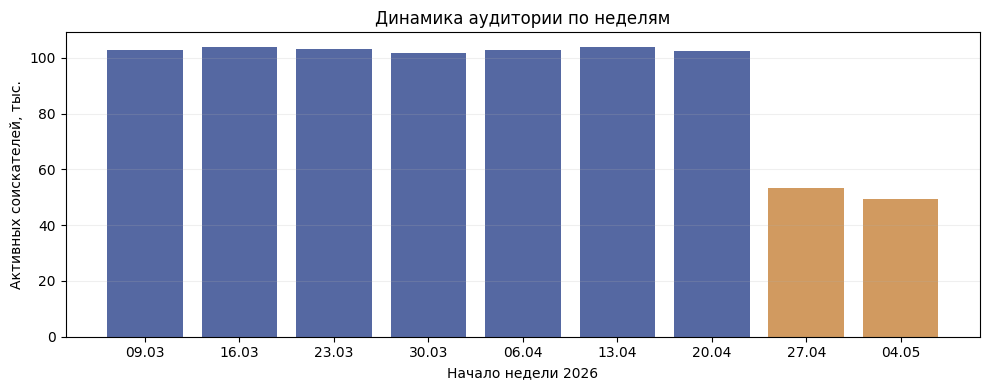

In [12]:

weekly = (app.assign(with_response=app['responses_app'].gt(0))
          .groupby('week_start', as_index=False)
          .agg(active=('user_id', 'nunique'),
               with_response=('with_response', 'sum')))
weekly['response_share_pct'] = 100 * weekly['with_response'] / weekly['active']

weekly_table = weekly.rename(columns={
    'week_start': 'Неделя с',
    'active': 'Активных соискателей',
    'with_response': 'Соискателей с откликом',
    'response_share_pct': 'Доля с откликом, %'
}).copy()
weekly_table['Неделя с'] = weekly_table['Неделя с'].dt.strftime('%d.%m.%Y')
display(weekly_table.round(2))

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(weekly['week_start'].dt.strftime('%d.%m'), weekly['active'] / 1000,
       color=['#5568A2'] * 7 + ['#D19A60'] * 2)
ax.set(xlabel='Начало недели 2026', ylabel='Активных соискателей, тыс.',
       title='Динамика аудитории по неделям')
ax.grid(axis='y', alpha=0.2)
plt.tight_layout()
fig.savefig('weekly_activity.png', dpi=160, bbox_inches='tight')
plt.show()

## 2. MDE для 1–5 недель

In [13]:
history_start = pd.Timestamp('2026-04-06')

def participants_for_period(weeks):
    """Одна строка на участника с хотя бы одним откликом за weeks недель."""
    history_end = history_start + pd.Timedelta(weeks=weeks)
    period = app.loc[
        (app['week_start'] >= history_start) & (app['week_start'] < history_end),
        ['user_id', 'responses_app', 'relevant_responses_app', 'invitations_app']
    ]
    # Суммируем все недели пользователя; тот, кто не отправил откликов, не входит
    # в выборку. Нули по релевантным откликам и приглашениям сохраняем.
    per_user = period.groupby('user_id', sort=False).sum()
    return per_user.loc[per_user['responses_app'] > 0].copy()

In [14]:
alpha = 0.05
power = 0.80
z_two_sided = NormalDist().inv_cdf(1 - alpha / 2)  # целевая метрика
z_one_sided = NormalDist().inv_cdf(1 - alpha)      # приглашения
z_power = NormalDist().inv_cdf(power)

results = []
for weeks in range(1, 6):
    participants = participants_for_period(weeks)
    N = len(participants)
    n_A = N // 2       # контроль (A)
    n_B = N - n_A     # тест (B)
    row = {'weeks': weeks, 'N': N, 'n_A': n_A, 'n_B': n_B}

    for prefix, metric, z_level in [
        ('relevant', 'relevant_responses_app', z_two_sided),
        ('invitations', 'invitations_app', z_one_sided),
    ]:
        y = participants[metric].to_numpy(dtype=float)
        mean_y = y.mean()
        sd_y = y.std(ddof=1)
        SE = sd_y * math.sqrt(1 / n_A + 1 / n_B)
        mde_abs = (z_level + z_power) * SE
        row.update({
            f'{prefix}_mean': mean_y,
            f'{prefix}_sd': sd_y,
            f'{prefix}_SE': SE,
            f'{prefix}_mde_abs': mde_abs,
            f'{prefix}_mde_pct': 100 * mde_abs / mean_y,
        })
    results.append(row)

mde = pd.DataFrame(results).set_index('weeks')

# Промежуточные величины для проверки подстановки за 3 недели.
columns = ['N', 'n_A', 'n_B', 'relevant_mean', 'relevant_sd', 'relevant_SE',
           'relevant_mde_abs', 'invitations_mean', 'invitations_sd',
           'invitations_SE', 'invitations_mde_abs']
detailed = mde[columns].copy()
detailed.columns = ['Участники N', 'Контроль A', 'Тест B', 'Среднее рел.',
                    's рел.', 'SE рел.', 'MDE рел., шт.', 'Среднее приг.',
                    's приг.', 'SE приг.', 'MDE приг., шт.']
display(detailed.round(4))

,Участники N,Контроль A,Тест B,Среднее рел.,s рел.,SE рел.,"MDE рел., шт.",Среднее приг.,s приг.,SE приг.,"MDE приг., шт."
weeks,,,,,,,,,,,
1,94868,47434,47434,2.9163,3.1229,0.0203,0.0568,0.3592,0.8569,0.0056,0.0138
2,156331,78165,78166,3.5801,4.3104,0.0218,0.0611,0.4391,1.0750,0.0054,0.0135
3,197889,98944,98945,4.2183,5.4340,0.0244,0.0684,0.5173,1.2978,0.0058,0.0145
4,208531,104265,104266,4.6832,6.8423,0.0300,0.0840,0.5770,1.5397,0.0067,0.0168
5,216512,108256,108256,5.0998,8.3441,0.0359,0.1005,0.6295,1.7923,0.0077,0.0192


In [15]:
# Таблица MDE
summary = mde[['N', 'n_A', 'relevant_mde_pct', 'invitations_mde_pct']].copy()
summary.columns = ['Участников N', 'Контроль A', 'MDE релевантных, %', 'MDE приглашений, %']
summary.index.name = 'Недель'
display(summary.round(3))

# Две границы: рост целевой метрики 1,7%, допустимое снижение 3%
fits = ((mde['relevant_mde_pct'] <= 1.7) & (mde['invitations_mde_pct'] <= 3.0))
print('Длительности, для которых оба MDE не превышают порогов:',
      list(mde.index[fits]))
print('MDE за 3 недели:', f"{mde.loc[3, 'relevant_mde_pct']:.3f}%", 'и',
      f"{mde.loc[3, 'invitations_mde_pct']:.3f}%")

,Участников N,Контроль A,"MDE релевантных, %","MDE приглашений, %"
Недель,,,,
1,94868,47434,1.948,3.852
2,156331,78165,1.706,3.079
3,197889,98944,1.623,2.805
4,208531,104265,1.793,2.906
5,216512,108256,1.970,3.043


Длительности, для которых оба MDE не превышают порогов: [3]
MDE за 3 недели: 1.623% и 2.805%


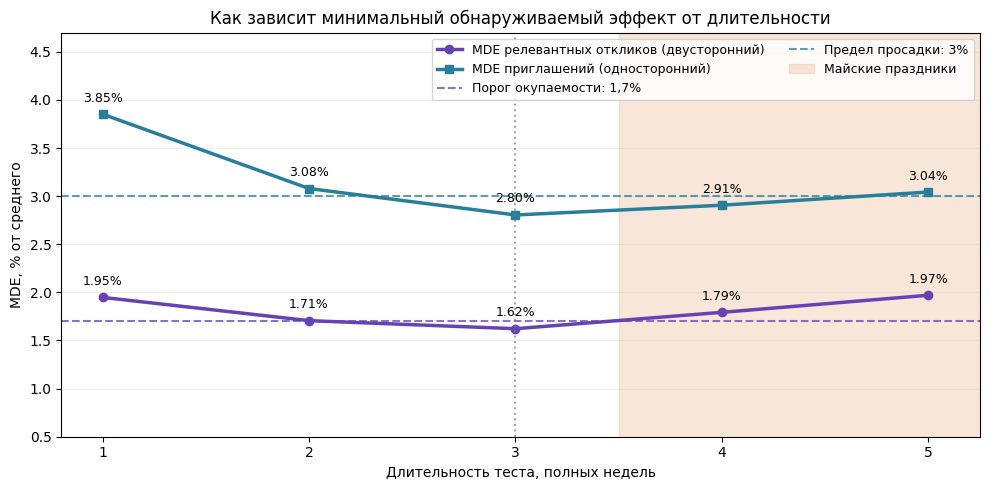

In [16]:
fig, ax = plt.subplots(figsize=(10, 5))
weeks = mde.index.to_numpy()
ax.plot(weeks, mde['relevant_mde_pct'], 'o-', linewidth=2.5, color='#6742B5',
        label='MDE релевантных откликов (двусторонний)')
ax.plot(weeks, mde['invitations_mde_pct'], 's-', linewidth=2.5, color='#277F9B',
        label='MDE приглашений (односторонний)')
ax.axhline(1.7, ls='--', color='#6742B5', alpha=0.75,
           label='Порог окупаемости: 1,7%')
ax.axhline(3.0, ls='--', color='#277F9B', alpha=0.75,
           label='Предел просадки: 3%')
ax.axvspan(3.5, 5.4, alpha=0.28, color='#E8A978', label='Майские праздники')
ax.axvline(3, ls=':', color='gray', alpha=0.7)
for x, y in zip(weeks, mde['relevant_mde_pct']):
    ax.annotate(f'{y:.2f}%', (x, y), xytext=(0, 9),
                textcoords='offset points', ha='center', fontsize=9)
for x, y in zip(weeks, mde['invitations_mde_pct']):
    ax.annotate(f'{y:.2f}%', (x, y), xytext=(0, 9),
                textcoords='offset points', ha='center', fontsize=9)
ax.set(xticks=[1, 2, 3, 4, 5], xlim=(0.8, 5.25), ylim=(0.5, 4.7),
       xlabel='Длительность теста, полных недель',
       ylabel='MDE, % от среднего',
       title='Как зависит минимальный обнаруживаемый эффект от длительности')
ax.grid(axis='y', alpha=0.2)
ax.legend(fontsize=9, loc='upper right', ncol=2)
plt.tight_layout()
fig.savefig('mde_graph.png', dpi=160, bbox_inches='tight')
plt.show()

## 3. A/A-тест на исторических данных и проверка SRM

In [17]:
participants_3w = participants_for_period(3)
y = participants_3w['relevant_responses_app'].to_numpy(dtype=float)

rng = np.random.default_rng(2027)
p_values = []
first_split = None
for repeat in range(1000):
    # Каждый пользователь независимо попадает в контроль A или группу B 
    in_B = rng.integers(0, 2, size=len(y), dtype=np.int8).astype(bool)
    y_A, y_B = y[~in_B], y[in_B]
    mean_A, mean_B = y_A.mean(), y_B.mean()
    SE = math.sqrt(y_A.var(ddof=1) / len(y_A) + y_B.var(ddof=1) / len(y_B))
    z = (mean_B - mean_A) / SE
    p = math.erfc(abs(z) / math.sqrt(2))  # двустороннее p-value
    p_values.append(p)

    if repeat == 0:
        first_split = {'n_A': len(y_A), 'n_B': len(y_B),
                       'mean_A': mean_A, 'mean_B': mean_B, 'p': p}

p_values = np.asarray(p_values)
false_count = int((p_values < 0.05).sum())
print('Период A/A: 06.04.2026–26.04.2026')
print('Участников:', len(y))
print('Повторов A/A:', len(p_values))
print('Случаев с p < 0,05:', false_count)
print('Доля ложных срабатываний:', f'{100 * false_count / len(p_values):.1f}%')
print('Ожидаемая доля при α = 0,05: 5%')
print('Первое разбиение:')
print('  Контроль A:', first_split['n_A'])
print('  Группа B:', first_split['n_B'])
print('  Среднее релевантных откликов A:', f"{first_split['mean_A']:.4f}")
print('  Среднее релевантных откликов B:', f"{first_split['mean_B']:.4f}")
print('  p-value:', f"{first_split['p']:.4f}")

Период A/A: 06.04.2026–26.04.2026
Участников: 197889
Повторов A/A: 1000
Случаев с p < 0,05: 43
Доля ложных срабатываний: 4.3%
Ожидаемая доля при α = 0,05: 5%
Первое разбиение:
  Контроль A: 99214
  Группа B: 98675
  Среднее релевантных откликов A: 4.2166
  Среднее релевантных откликов B: 4.2200
  p-value: 0.8876


In [18]:
# Сравнение фактического распределения с пропорцией 50/50.
n_A, n_B = first_split['n_A'], first_split['n_B']
E = (n_A + n_B) / 2  # может быть дробной
chi2 = (n_A - E)**2 / E + (n_B - E)**2 / E
p_srm = math.erfc(math.sqrt(chi2 / 2))  # p-value для хи-квадрат с 1 степенью свободы

print(f'Группа A: {n_A:,}; группа B: {n_B:,}'.replace(',', ' '))
print(f'Ожидаемая частота при 50/50: {E:,.1f} на группу'.replace(',', ' '))
print('χ²:', f'{chi2:.4f}')
print('p-value SRM:', f'{p_srm:.4f}')
print('SRM не обнаружен' if p_srm >= 0.001 else 'Возможное нарушение распределения — проверить SRM')

Группа A: 99 214; группа B: 98 675
Ожидаемая частота при 50/50: 98 944.5 на группу
χ²: 1.4681
p-value SRM: 0.2256
SRM не обнаружен
